# Kaggle Competition: Facial Feature Classification Challenge

In [4]:
import numpy as np
import pandas as pd
from pathlib import Path

data_folder = Path("../enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch")  # Competition data folder (relative to this notebook)

training_images_folder = data_folder / "train" / "train"                    # Training images folder path
testing_images_folder = data_folder / "test" / "test"                       # Testing images folder path

sample_submission_csv_path = data_folder / "sample_submission.csv"          # Sample submission CSV file path
train_labels_csv_path = data_folder / "train_labels.csv"                    # Training labels CSV file path

df_sample_submission = pd.read_csv(sample_submission_csv_path)  # Load sample submission CSV into a DataFrame
df_train_labels = pd.read_csv(train_labels_csv_path)            # Load training labels CSV into a DataFrame

## Image Analysis

Collect per-image information for every image in the train and test folders (file size, dimensions, pixel count, colour mode, brightness/colour statistics, duplicates) and save it to `images_info.csv`.

In [24]:
import hashlib
from PIL import Image

images_info_csv_path = Path("images_info.csv")  # Output CSV file path


def get_image_info(image_path, split):
    """Return a dictionary of information about one image."""
    file_bytes = image_path.read_bytes()

    info = {}
    info["split"] = split                                       # "train" or "test"
    info["image_id"] = int(image_path.stem)                     # "00001.jpg" -> 1 (matches the CSV files)
    info["file_name"] = image_path.name
    info["file_size_bytes"] = len(file_bytes)
    info["file_size_kb"] = round(len(file_bytes) / 1024, 3)
    info["md5_hash"] = hashlib.md5(file_bytes).hexdigest()      # Identical files have identical hashes

    try:
        image = Image.open(image_path)
        info["format"] = image.format                           # e.g. JPEG
        info["mode"] = image.mode                               # e.g. RGB, L (greyscale)
        info["width"] = image.width
        info["height"] = image.height
        info["channels"] = len(image.getbands())                # Number of color channels

        # Convert the image to a NumPy array and calculate brightness and color statistics
        # Pixel values as a height x width x 3 array (red, green, blue), each 0 to 255
        pixels = np.array(image.convert("RGB"), dtype=np.float32)   
        red = pixels[:, :, 0]
        green = pixels[:, :, 1]
        blue = pixels[:, :, 2]
        grey = (red + green + blue) / 3

        info["mean_brightness"] = round(float(grey.mean()), 3)  # 0 (black) to 255 (white)
        info["std_brightness"] = round(float(grey.std()), 3)    # Contrast
        info["min_pixel"] = int(pixels.min())                   # Minimum pixel value (0 to 255)
        info["max_pixel"] = int(pixels.max())                   # Maximum pixel value (0 to 255)    
        info["mean_red"] = round(float(red.mean()), 3)
        info["mean_green"] = round(float(green.mean()), 3)
        info["mean_blue"] = round(float(blue.mean()), 3)

        # A greyscale image stored as RGB has the same values in all three channels
        same_red_green = np.array_equal(red, green)                     # bool (true if all pixels are the saem in both channels)
        same_green_blue = np.array_equal(green, blue)
        info["is_greyscale"] = bool(same_red_green and same_green_blue) # True if all three channels have the same values

        # By default, images are assumed to be valid. If an exception is found, the image is corrupt.
        info["is_corrupt"] = False
        image.close()
    except Exception:
        info["is_corrupt"] = True

    return info


# Look up a training image's class from its ID
class_of_image = {}
for image_id, class_name in zip(df_train_labels["image_id"], df_train_labels["class"]):
    class_of_image[int(image_id)] = class_name

# Collect information for every train and test image
image_records = []
for split in ["train", "test"]:                                     # Loop over the two splits of the dataset
    if split == "train":
        folder = training_images_folder
    else:
        folder = testing_images_folder

    image_paths = sorted(folder.glob("*.jpg"))                      # Get a list of all JPG files in the folder, sorted by name (therefore it goes 00001.jpg, 00002.jpg, 00003.jpg, etc.)
    print(f"Analysing {len(image_paths)} {split} images...")        # log the number of images being analysed

    for image_path in image_paths:
        info = get_image_info(image_path, split)
        if split == "train":
            info["class"] = class_of_image[info["image_id"]]        # label train split images with their class (cat or dog)
        else:
            info["class"] = None                                    # Test images have no label
        image_records.append(info)                                  # Add the image's info to the list of records

df_images_info = pd.DataFrame(image_records)                        # Create a DataFrame from the list of image info dictionaries

# Extra columns worked out from the ones above
df_images_info["total_pixels"] = df_images_info["width"] * df_images_info["height"]
df_images_info["aspect_ratio"] = (df_images_info["width"] / df_images_info["height"]).round(3)   # Width / height
df_images_info["short_side"] = df_images_info[["width", "height"]].min(axis=1)                   # Length of the shorter side, in pixels
df_images_info["is_duplicate"] = df_images_info.duplicated("md5_hash", keep=False)               # True for every copy of a repeated file

column_order = [                                                                                 # Reorder the columns for easier reading
    "split", "image_id", "file_name", "class", "format", "mode", "channels",
    "width", "height", "total_pixels", "aspect_ratio", "short_side", "file_size_bytes", "file_size_kb",
    "mean_brightness", "std_brightness", "min_pixel", "max_pixel",
    "mean_red", "mean_green", "mean_blue", "is_greyscale", "is_corrupt", "is_duplicate", "md5_hash",
]
df_images_info = df_images_info[column_order]
df_images_info.to_csv(images_info_csv_path, index=False)
print(f"Saved {len(df_images_info)} rows to {images_info_csv_path}")

Analysing 63660 train images...
Analysing 29443 test images...
Saved 93103 rows to images_info.csv


Quick summary of the scan.

In [6]:
print("Images per split:")
print(df_images_info["split"].value_counts())
print()
print("Colour modes:")
print(df_images_info["mode"].value_counts())
print()
print("Greyscale images:", df_images_info["is_greyscale"].sum())
print("Corrupt images:  ", df_images_info["is_corrupt"].sum())
print("Duplicate images:", df_images_info["is_duplicate"].sum())

Images per split:
split
train    63660
test     29443
Name: count, dtype: int64

Colour modes:
mode
RGB    93103
Name: count, dtype: int64

Greyscale images: 1434
Corrupt images:   0
Duplicate images: 154


## Task 1: Dataset Exploration and Understanding

### Settings and data used in this section

In [25]:
import math
import matplotlib.pyplot as plt
from PIL import Image

# Folder and CSV paths 
figures_folder = Path("figures")                  # Folder to store all figures and plots generated in this notebook
images_info_csv_path = Path("images_info.csv")    # Created by the image analysis above
sharpness_csv_path = Path("image_sharpness.csv")  # Created in section 1.6 (saved so it only runs once)

# Global Settings - Define constants for reproducibility and image analysis
RANDOM_SEED = 42                                  # Same seed = same random sample images every run
SMALL_IMAGE_SIZE = 32                             # Images with a shorter side below this (pixels) count as "small"
BLUR_THRESHOLD = 20                               # Images with sharpness below this count as "blurry"

CLASSES = ["CatEye", "CatFace", "CatMouth", "CatNose", "DogEye", "DogFace", "DogMouth", "DogNose"]
PARTS = ["Eye", "Face", "Mouth", "Nose"]
CAT_COLOUR = "#4C72B0"                            # Blue
DOG_COLOUR = "#DD8452"                            # Orange

# Load image information as a dataframe
df_info = pd.read_csv(images_info_csv_path, dtype={"class": "string"})   # "class" is empty for test images

# individual dataframes for train and test splits
df_train_info = df_info[df_info["split"] == "train"]
df_test_info = df_info[df_info["split"] == "test"]

# Print the number of training and test images
print("Training images:", len(df_train_info))
print("Test images:    ", len(df_test_info))

print("Training images")
display(df_train_info)

print("Test images")
display(df_test_info)

Training images: 63660
Test images:     29443
Training images


,split,image_id,file_name,class,format,mode,channels,width,height,total_pixels,...,std_brightness,min_pixel,max_pixel,mean_red,mean_green,mean_blue,is_greyscale,is_corrupt,is_duplicate,md5_hash
0,train,1,00001.jpg,DogEye,JPEG,RGB,3,36,36,1296,...,39.430,0,236,118.787,121.071,135.931,False,False,False,005e6966847edf1c67cb69dc54ab2d8f
1,train,2,00002.jpg,DogMouth,JPEG,RGB,3,214,157,33598,...,66.703,0,255,140.455,126.462,104.217,False,False,False,0db24ae499fa38d176c4db7bd5c050ce
2,train,3,00003.jpg,DogFace,JPEG,RGB,3,97,97,9409,...,67.946,0,255,146.143,118.291,95.413,False,False,False,d97191734c94207ca601a35508ec7174
3,train,4,00004.jpg,DogNose,JPEG,RGB,3,110,110,12100,...,48.471,0,233,104.057,98.559,87.784,False,False,False,5aeb640a2b5d4ee4a9d6b02acb501329
4,train,5,00005.jpg,DogNose,JPEG,RGB,3,42,42,1764,...,24.338,9,180,88.770,84.960,101.673,False,False,False,342155bcc74eb7507ffd6dfc61e8da48
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63655,train,63656,63656.jpg,CatEye,JPEG,RGB,3,24,24,576,...,24.455,0,187,64.128,68.220,72.830,False,False,False,a8c0e2b26469f1412c6e163ca7952568
63656,train,63657,63657.jpg,DogMouth,JPEG,RGB,3,70,52,3640,...,51.162,6,199,133.837,127.879,122.508,False,False,False,1c0a183c35b874db7d6813daecaf323e
63657,train,63658,63658.jpg,DogEye,JPEG,RGB,3,36,36,1296,...,32.986,0,255,42.245,44.748,36.311,False,False,False,75dab4924e0e07ad40e607d430e4f2ab
63658,train,63659,63659.jpg,DogMouth,JPEG,RGB,3,170,125,21250,...,32.882,27,184,114.201,112.905,110.079,False,False,False,1e9871919ea71cce0764530466fad275


Test images


,split,image_id,file_name,class,format,mode,channels,width,height,total_pixels,...,std_brightness,min_pixel,max_pixel,mean_red,mean_green,mean_blue,is_greyscale,is_corrupt,is_duplicate,md5_hash
63660,test,1,00001.jpg,<NA>,JPEG,RGB,3,112,112,12544,...,27.806,16,187,76.179,66.201,69.405,False,False,False,e0e6929328e664c05c247a28428b795c
63661,test,2,00002.jpg,<NA>,JPEG,RGB,3,96,69,6624,...,45.589,0,255,162.046,118.128,60.289,False,False,False,98d19b14615f85d63b2f167374be6dee
63662,test,3,00003.jpg,<NA>,JPEG,RGB,3,34,34,1156,...,23.827,0,178,51.685,50.140,52.231,False,False,False,25b4231809e70ad5b1dc8e8ab4bfbaea
63663,test,4,00004.jpg,<NA>,JPEG,RGB,3,119,119,14161,...,67.064,0,255,112.816,105.563,102.131,False,False,False,fb8e404d9d50d45070f8add0545e4d65
63664,test,5,00005.jpg,<NA>,JPEG,RGB,3,210,140,29400,...,85.674,0,255,95.460,94.706,97.022,False,False,False,1f345225fc5560627ac753fc519255c9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93098,test,29439,29439.jpg,<NA>,JPEG,RGB,3,30,20,600,...,42.386,0,255,66.228,37.542,20.112,False,False,True,352a41b1efa27813ed6d18ed06c2764b
93099,test,29440,29440.jpg,<NA>,JPEG,RGB,3,75,60,4500,...,75.000,0,242,143.183,127.280,79.916,False,False,False,cf3cacff1c56bd620106bcb1f250e21d
93100,test,29441,29441.jpg,<NA>,JPEG,RGB,3,206,205,42230,...,94.725,0,255,112.005,113.212,116.274,False,False,False,ea3c253c485d0e0cd00d457b33aa485f
93101,test,29442,29442.jpg,<NA>,JPEG,RGB,3,1260,1190,1499400,...,41.911,0,255,100.757,75.703,64.006,False,False,False,1ef7822f85f24dc1639900410efbc3fe


Two helper functions used to show and save grids of images.

In [8]:
def get_image_path(split, file_name):
    """Return the full path of an image."""
    if split == "train":
        return training_images_folder / file_name
    else:
        return testing_images_folder / file_name


def show_images(df_rows, captions, n_columns, title, save_name):
    """Show one image per row of df_rows in a grid, with a caption under each, and save the figure."""
    n_images = len(df_rows)
    n_rows = math.ceil(n_images / n_columns)
    plt.figure(figsize=(n_columns * 1.6, n_rows * 1.95))

    for i in range(n_images):
        row = df_rows.iloc[i]
        image = Image.open(get_image_path(row["split"], row["file_name"])).convert("RGB")

        plt.subplot(n_rows, n_columns, i + 1)     # Grid positions start at 1
        plt.imshow(image)
        plt.title(captions[i], fontsize=7)
        plt.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(figures_folder / save_name, dpi=150, bbox_inches="tight")
    plt.show()

### 1.2 Structure of the training and test data

Check that the files on disk match the CSV files.

In [30]:
# Get a list of all JPG files in the relevant folder
train_files = list(training_images_folder.glob("*.jpg")) 
test_files = list(testing_images_folder.glob("*.jpg"))              

# Print the number of images found on disk and the number of rows in the CSV files to compare
print("Image Quantity Checks:")
print("Training images on disk:      ", len(train_files))          
print("Test images on disk:          ", len(test_files))   
print("Rows in train_labels.csv:     ", len(df_train_labels))
print("Rows in sample_submission.csv:", len(df_sample_submission))

# Turn file names into IDs: "00001.jpg" -> 1
train_ids_on_disk = set()
for path in train_files:
    train_ids_on_disk.add(int(path.stem))

test_ids_on_disk = set()
for path in test_files:
    test_ids_on_disk.add(int(path.stem))

labelled_ids = set(df_train_labels["image_id"].astype(int))                                     # set of image IDs that have labels in train_labels.csv
submission_ids = set(df_sample_submission["image_id"].astype(int))                              # set of image IDs that are listed in the sample submission

# Check that the image IDs in the CSV files match the image IDs on disk
print("\nImage ID checks:")
print("Every training image has a label:        ", train_ids_on_disk == labelled_ids)         # Check if all training images have labels
print("Sample submission lists every test image:", test_ids_on_disk == submission_ids)          # Check if the sample submission lists all test images
print("Missing labels:                          ", df_train_labels["class"].isna().sum())       # Count missing labels
print("IDs used in both train and test:         ", len(train_ids_on_disk & test_ids_on_disk))   # image IDs that are used in both the training and test sets
print("Label values:", sorted(df_train_labels["class"].unique()))

# looking at the image types and colour modes in the dataset
print("\nImage type:")
print("Image formats:", df_info["format"].value_counts().to_dict())
print("Colour modes: ", df_info["mode"].value_counts().to_dict())

# Examine the first few rows of the CSV files to check their structure and contents
print("\nFirst rows of train_labels.csv:")
print(df_train_labels.head())

# Same as above, but for sample_submission.csv
print("\nFirst rows of sample_submission.csv:")
print(df_sample_submission.head())

Image Quantity Checks:
Training images on disk:       63660
Test images on disk:           29443
Rows in train_labels.csv:      63660
Rows in sample_submission.csv: 29443

Image ID checks:
Every training image has a label:         True
Sample submission lists every test image: True
Missing labels:                           0
IDs used in both train and test:          29443
Label values: ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']

Image type:
Image formats: {'JPEG': 93103}
Colour modes:  {'RGB': 93103}

First rows of train_labels.csv:
   image_id     class
0         1    DogEye
1         2  DogMouth
2         3   DogFace
3         4   DogNose
4         5   DogNose

First rows of sample_submission.csv:
   image_id     class
0         1    DogEye
1         2   CatNose
2         3   CatNose
3         4   DogFace
4         5  DogMouth


### 1.3 Number of images per class

In [48]:
total_train = len(df_train_info)        # Create a variable to hold the total number of training images for later calculations

# Count the images in each class
class_counts = {}
for class_name in CLASSES:
    class_counts[class_name] = int((df_train_info["class"] == class_name).sum())

# Output the counts and percentages of each class in a formatted table
print(f"{'Class':<10} {'Images':>7} {'Percent':>8}")
for class_name in CLASSES:
    count = class_counts[class_name]
    percent = count / total_train * 100
    print(f"{class_name:<10} {count:>7} {percent:>7.1f}%")

# Counting total number of images for cats and dogs
cat_total = 0
dog_total = 0
for class_name in CLASSES:                      # For each class, add its count to either the cat or dog total
    if class_name.startswith("Cat"):
        cat_total += class_counts[class_name]
    else:
        dog_total += class_counts[class_name]
print("\nTotal number of images for cats and dogs:")
print(f"Cat images: {cat_total} ({cat_total / total_train * 100:.1f}%)")   # Print total number of cats as number and percentage
print(f"Dog images: {dog_total} ({dog_total / total_train * 100:.1f}%)")   # Print total number of dogs as number and percentage

# Largest and smallest class counts
Largest_class = max(class_counts, key=class_counts.get)  # Get the largest class name with the largest count
Smallest_class = min(class_counts, key=class_counts.get)  # Get the smallest class name with the smallest count
largest = class_counts[Largest_class]
smallest = class_counts[Smallest_class]
print("\nLargest class / smallest class:")
print(f"{Largest_class} / {Smallest_class}:  {largest / smallest:.2f}")

Class       Images  Percent
CatEye       13884    21.8%
CatFace       6942    10.9%
CatMouth      6942    10.9%
CatNose       6942    10.9%
DogEye       11580    18.2%
DogFace       5790     9.1%
DogMouth      5790     9.1%
DogNose       5790     9.1%

Total number of images for cats and dogs:
Cat images: 34710 (54.5%)
Dog images: 28950 (45.5%)

Largest class / smallest class:
CatEye / DogFace:  2.40


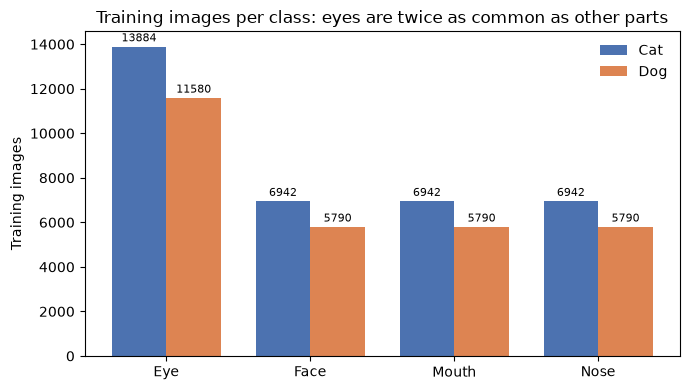

In [11]:
# Bar chart: one group of bars per facial part, cat and dog side by side
cat_counts = []
dog_counts = []
for part in PARTS:
    cat_counts.append(class_counts["Cat" + part])
    dog_counts.append(class_counts["Dog" + part])

x_positions = np.arange(len(PARTS))   # 0, 1, 2, 3
bar_width = 0.38

fig, ax = plt.subplots(figsize=(7, 4))
cat_bars = ax.bar(x_positions - bar_width / 2, cat_counts, bar_width, label="Cat", color=CAT_COLOUR)
dog_bars = ax.bar(x_positions + bar_width / 2, dog_counts, bar_width, label="Dog", color=DOG_COLOUR)
ax.bar_label(cat_bars, fontsize=8, padding=2)   # Write the count above each bar
ax.bar_label(dog_bars, fontsize=8, padding=2)

ax.set_xticks(x_positions)
ax.set_xticklabels(PARTS)
ax.set_ylabel("Training images")
ax.set_title("Training images per class: eyes are twice as common as other parts")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(figures_folder / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### 1.4 Representative sample images from each class

Six random images per class (fixed seed). Every tile is shown at the same display size, so the caption gives the image's real size in pixels.

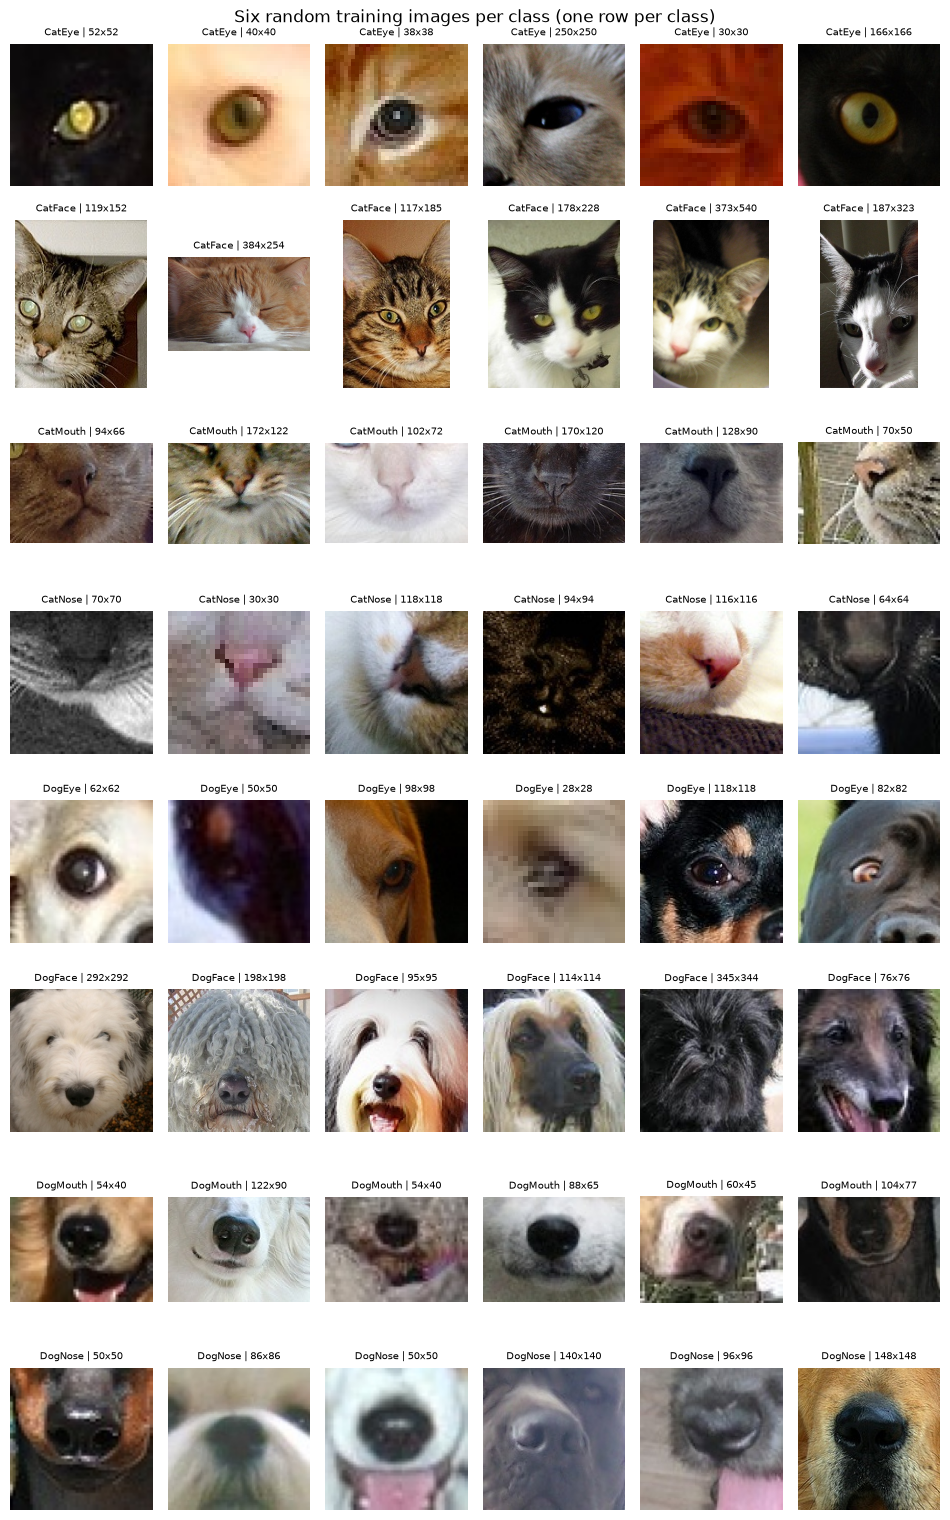

In [12]:
sample_tables = []
for class_name in CLASSES:
    df_class = df_train_info[df_train_info["class"] == class_name]
    sample_tables.append(df_class.sample(6, random_state=RANDOM_SEED))
df_samples = pd.concat(sample_tables)

captions = []
for i in range(len(df_samples)):
    row = df_samples.iloc[i]
    captions.append(f"{row['class']} | {row['width']}x{row['height']}")

show_images(df_samples, captions, n_columns=6,
            title="Six random training images per class (one row per class)",
            save_name="sample_images_per_class.png")

### 1.5 Image sizes

Sizes vary a lot, so this looks at the shorter side of each image.

In [13]:
print(f"{'Class':<10} {'Median W':>9} {'Median H':>9} {'Smallest':>9} {'Largest':>8} {'Small':>6} {'Small %':>8}")
for class_name in CLASSES:
    df_class = df_train_info[df_train_info["class"] == class_name]
    median_width = df_class["width"].median()
    median_height = df_class["height"].median()
    smallest_side = df_class["short_side"].min()
    largest_side = df_class["short_side"].max()
    n_small = (df_class["short_side"] < SMALL_IMAGE_SIZE).sum()
    percent_small = n_small / len(df_class) * 100
    print(f"{class_name:<10} {median_width:>9.0f} {median_height:>9.0f} {smallest_side:>9} {largest_side:>8} {n_small:>6} {percent_small:>7.1f}%")
print(f"(Smallest/Largest = shorter side in pixels. Small = shorter side under {SMALL_IMAGE_SIZE} px.)")
print()

n_sizes = len(df_info.groupby(["width", "height"]))
n_square = (df_train_info["width"] == df_train_info["height"]).sum()
n_small = (df_train_info["short_side"] < SMALL_IMAGE_SIZE).sum()
print("Different (width, height) sizes:", n_sizes)
print(f"Square training images: {n_square} ({n_square / total_train * 100:.1f}%)")
print(f"Small training images:  {n_small} ({n_small / total_train * 100:.1f}%)")

Class       Median W  Median H  Smallest  Largest  Small  Small %
CatEye            68        68         4      340   1459    10.5%
CatFace          182       215        22      945     14     0.2%
CatMouth         114        80         4      394    484     7.0%
CatNose           68        68         4      340    731    10.5%
DogEye            62        62        14      886    862     7.4%
DogFace          155       155        39     2219      0     0.0%
DogMouth         104        77        17     1107    149     2.6%
DogNose           62        62        14      886    431     7.4%
(Smallest/Largest = shorter side in pixels. Small = shorter side under 32 px.)

Different (width, height) sizes: 14347
Square training images: 41710 (65.5%)
Small training images:  4130 (6.5%)


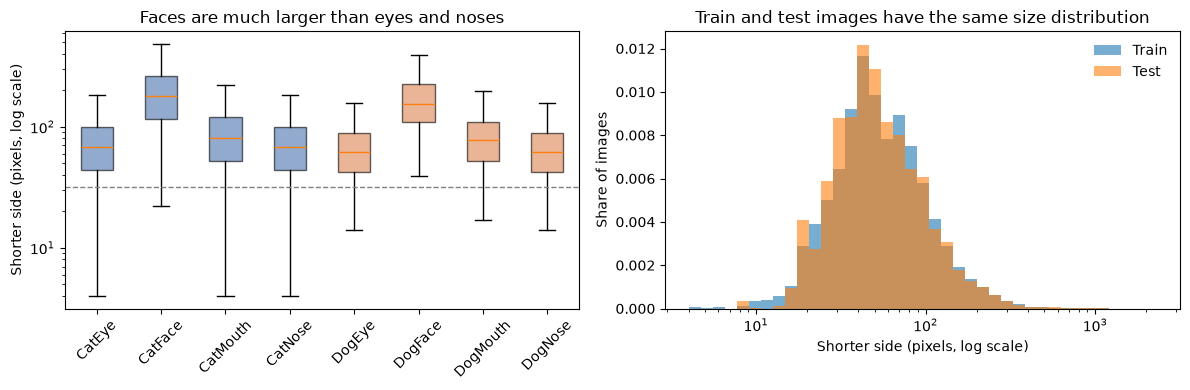

In [14]:
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 4))

# Left: box plot of the shorter side for each class
box_data = []
for class_name in CLASSES:
    df_class = df_train_info[df_train_info["class"] == class_name]
    box_data.append(df_class["short_side"])

boxes = ax_left.boxplot(box_data, showfliers=False, patch_artist=True)
for i in range(len(CLASSES)):
    if CLASSES[i].startswith("Cat"):
        boxes["boxes"][i].set_facecolor(CAT_COLOUR)
    else:
        boxes["boxes"][i].set_facecolor(DOG_COLOUR)
    boxes["boxes"][i].set_alpha(0.6)

ax_left.set_xticks(range(1, len(CLASSES) + 1))
ax_left.set_xticklabels(CLASSES, rotation=45)
ax_left.set_yscale("log")
ax_left.set_ylabel("Shorter side (pixels, log scale)")
ax_left.axhline(SMALL_IMAGE_SIZE, color="grey", linestyle="--", linewidth=1)
ax_left.set_title("Faces are much larger than eyes and noses")

# Right: histogram of the shorter side, train vs test
bins = np.logspace(np.log10(4), np.log10(2300), 40)   # Evenly spaced bins on a log scale
ax_right.hist(df_train_info["short_side"], bins=bins, density=True, alpha=0.6, label="Train")
ax_right.hist(df_test_info["short_side"], bins=bins, density=True, alpha=0.6, label="Test")
ax_right.set_xscale("log")
ax_right.set_xlabel("Shorter side (pixels, log scale)")
ax_right.set_ylabel("Share of images")
ax_right.set_title("Train and test images have the same size distribution")
ax_right.legend(frameon=False)

plt.tight_layout()
plt.savefig(figures_folder / "image_sizes.png", dpi=150, bbox_inches="tight")
plt.show()

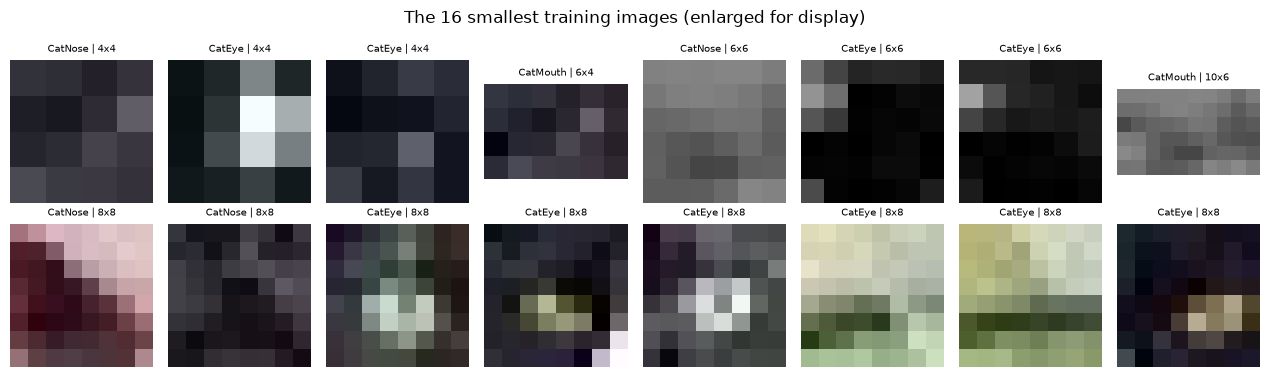

In [15]:
# The 16 smallest training images, enlarged so they can be seen
df_smallest = df_train_info.sort_values("total_pixels").head(16)

captions = []
for i in range(len(df_smallest)):
    row = df_smallest.iloc[i]
    captions.append(f"{row['class']} | {row['width']}x{row['height']}")

show_images(df_smallest, captions, n_columns=8,
            title="The 16 smallest training images (enlarged for display)",
            save_name="smallest_images.png")

### 1.6 Data quality issues

Checks for corrupt files, greyscale images, duplicates, blur, extreme brightness and unusual shapes.

In [16]:
print("Corrupt or unreadable files:", df_info["is_corrupt"].sum())
print()

n_grey_train = df_train_info["is_greyscale"].sum()
n_grey_test = df_test_info["is_greyscale"].sum()
print(f"Greyscale training images: {n_grey_train} ({n_grey_train / total_train * 100:.1f}%)")
print(f"Greyscale test images:     {n_grey_test} ({n_grey_test / len(df_test_info) * 100:.1f}%)")
print()
print("Greyscale training images per class:")
for class_name in CLASSES:
    df_class = df_train_info[df_train_info["class"] == class_name]
    print(f"  {class_name:<10} {df_class['is_greyscale'].sum()}")

Corrupt or unreadable files: 0

Greyscale training images: 1011 (1.6%)
Greyscale test images:     423 (1.4%)

Greyscale training images per class:
  CatEye     395
  CatFace    195
  CatMouth   202
  CatNose    209
  DogEye     5
  DogFace    1
  DogMouth   2
  DogNose    2


**Duplicates.** Files with the same MD5 hash are identical copies.

Duplicate groups: 77 (154 files)
  within train only:       15
  within test only:        62
  across train and test:   0
  with conflicting labels: 0
Extra training copies to remove before splitting: 15


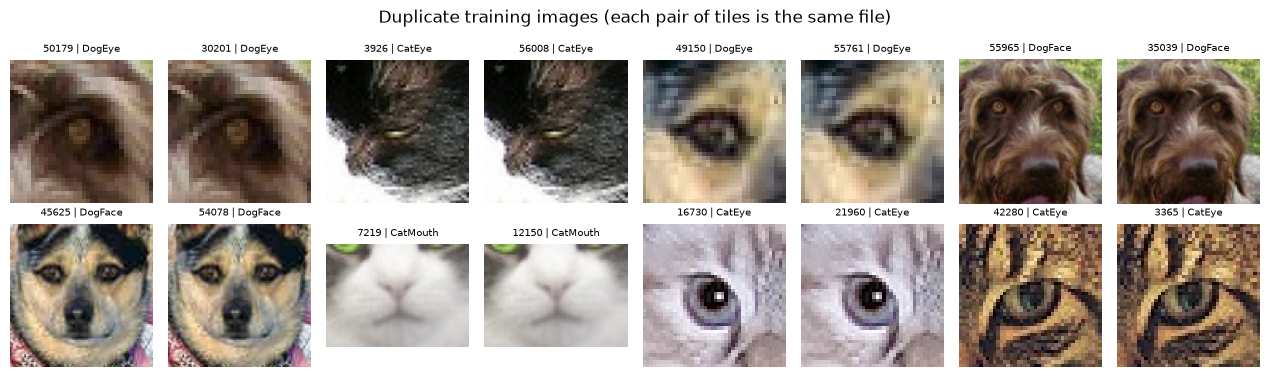

In [17]:
df_duplicates = df_info[df_info["is_duplicate"]]

train_only = 0
test_only = 0
train_and_test = 0
conflicting_labels = 0

for md5_hash in df_duplicates["md5_hash"].unique():
    df_group = df_duplicates[df_duplicates["md5_hash"] == md5_hash]   # All copies of one file
    splits = set(df_group["split"])
    if splits == {"train"}:
        train_only += 1
    elif splits == {"test"}:
        test_only += 1
    else:
        train_and_test += 1

    labels = set(df_group["class"].dropna())
    if len(labels) > 1:
        conflicting_labels += 1

print("Duplicate groups:", df_duplicates["md5_hash"].nunique(), f"({len(df_duplicates)} files)")
print("  within train only:      ", train_only)
print("  within test only:       ", test_only)
print("  across train and test:  ", train_and_test)
print("  with conflicting labels:", conflicting_labels)

# Extra copies = every copy after the first one of each file
extra_train_copies = df_train_info.duplicated("md5_hash").sum()
print("Extra training copies to remove before splitting:", extra_train_copies)

# Show some duplicate pairs (sorted by hash, so copies sit next to each other)
df_duplicate_examples = df_duplicates[df_duplicates["split"] == "train"].sort_values("md5_hash").head(16)
captions = []
for i in range(len(df_duplicate_examples)):
    row = df_duplicate_examples.iloc[i]
    captions.append(f"{row['image_id']} | {row['class']}")

show_images(df_duplicate_examples, captions, n_columns=8,
            title="Duplicate training images (each pair of tiles is the same file)",
            save_name="duplicate_images.png")

**Blur.** Sharpness is measured as the variance of the Laplacian, an edge-detection filter: a blurry or flat image has few edges, so a low value. Each image is resized to 64 x 64 first so big and small images can be compared. Measuring every image takes a few minutes, so the results are saved to `image_sharpness.csv` and loaded from there next time.

In [18]:
def measure_sharpness(image_path):
    """Return the variance of the Laplacian of an image (higher = sharper)."""
    image = Image.open(image_path).convert("L").resize((64, 64), Image.BILINEAR)   # "L" = greyscale
    pixels = np.array(image, dtype=np.float32)

    # Laplacian = (pixel above + below + left + right) - 4 x the pixel itself.
    # Each slice below is the 62 x 62 grid of those neighbours for every inner pixel.
    centre = pixels[1:-1, 1:-1]
    above = pixels[:-2, 1:-1]
    below = pixels[2:, 1:-1]
    left = pixels[1:-1, :-2]
    right = pixels[1:-1, 2:]
    laplacian = above + below + left + right - 4 * centre

    return float(laplacian.var())


if sharpness_csv_path.exists():
    df_sharpness = pd.read_csv(sharpness_csv_path)
    print("Loaded sharpness values from", sharpness_csv_path)
else:
    print("Measuring sharpness of every image (a few minutes)...")
    sharpness_records = []
    for split, image_id, file_name in zip(df_info["split"], df_info["image_id"], df_info["file_name"]):
        value = measure_sharpness(get_image_path(split, file_name))
        sharpness_records.append({"split": split, "image_id": image_id, "sharpness": value})
    df_sharpness = pd.DataFrame(sharpness_records)
    df_sharpness.to_csv(sharpness_csv_path, index=False)

# Add the sharpness column to the image information
df_info = df_info.merge(df_sharpness, on=["split", "image_id"])
df_train_info = df_info[df_info["split"] == "train"]
df_test_info = df_info[df_info["split"] == "test"]

Loaded sharpness values from image_sharpness.csv


Blurry training images (sharpness under 20): 868 (1.4%)
Blurry test images (sharpness under 20):     310 (1.1%)

Median sharpness per class:
  CatEye     468
  CatFace    994
  CatMouth   545
  CatNose    284
  DogEye     262
  DogFace    820
  DogMouth   527
  DogNose    301


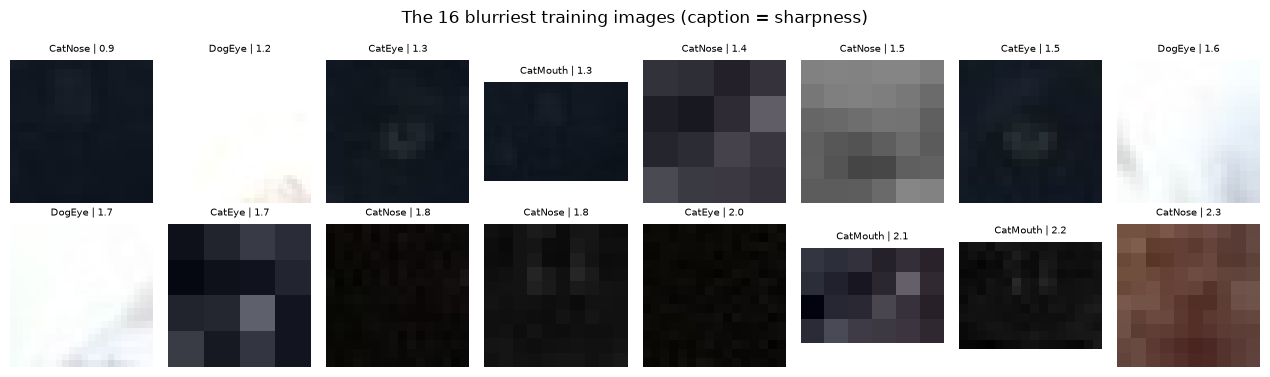

In [19]:
n_blurry_train = (df_train_info["sharpness"] < BLUR_THRESHOLD).sum()
n_blurry_test = (df_test_info["sharpness"] < BLUR_THRESHOLD).sum()
print(f"Blurry training images (sharpness under {BLUR_THRESHOLD}): {n_blurry_train} ({n_blurry_train / total_train * 100:.1f}%)")
print(f"Blurry test images (sharpness under {BLUR_THRESHOLD}):     {n_blurry_test} ({n_blurry_test / len(df_test_info) * 100:.1f}%)")
print()
print("Median sharpness per class:")
for class_name in CLASSES:
    df_class = df_train_info[df_train_info["class"] == class_name]
    print(f"  {class_name:<10} {df_class['sharpness'].median():.0f}")

# The 16 blurriest training images
df_blurriest = df_train_info.sort_values("sharpness").head(16)
captions = []
for i in range(len(df_blurriest)):
    row = df_blurriest.iloc[i]
    captions.append(f"{row['class']} | {row['sharpness']:.1f}")

show_images(df_blurriest, captions, n_columns=8,
            title="The 16 blurriest training images (caption = sharpness)",
            save_name="blurriest_images.png")

**Brightness and unusual shapes.**

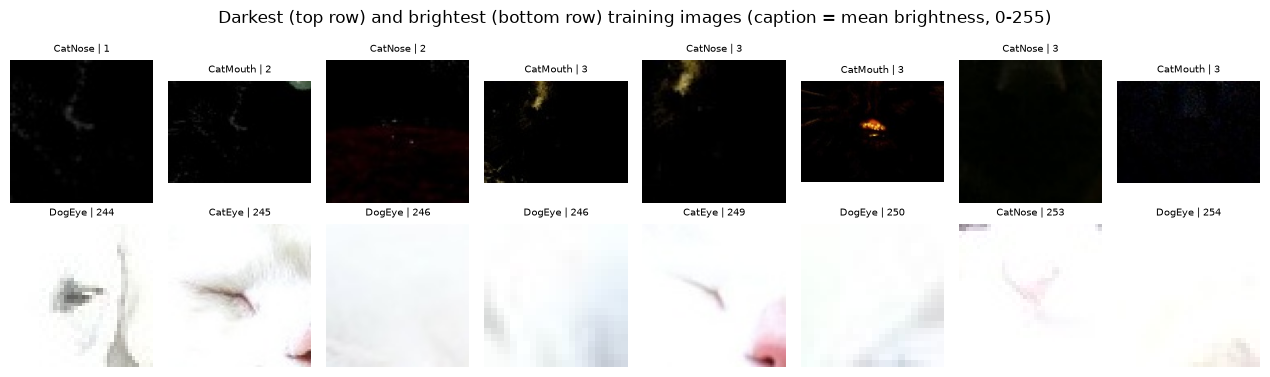

In [20]:
# Darkest 8 and brightest 8 training images
df_darkest = df_train_info.sort_values("mean_brightness").head(8)
df_brightest = df_train_info.sort_values("mean_brightness").tail(8)
df_dark_and_bright = pd.concat([df_darkest, df_brightest])

captions = []
for i in range(len(df_dark_and_bright)):
    row = df_dark_and_bright.iloc[i]
    captions.append(f"{row['class']} | {row['mean_brightness']:.0f}")

show_images(df_dark_and_bright, captions, n_columns=8,
            title="Darkest (top row) and brightest (bottom row) training images (caption = mean brightness, 0-255)",
            save_name="darkest_brightest_images.png")

Training images with an extreme aspect ratio: 40


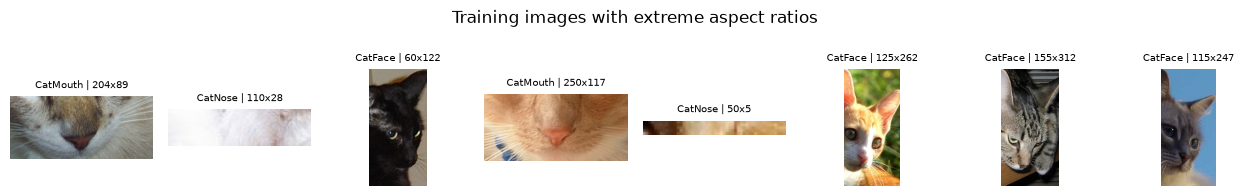

In [21]:
# Images more than twice as wide as tall, or more than twice as tall as wide
is_very_wide = df_train_info["aspect_ratio"] > 2
is_very_tall = df_train_info["aspect_ratio"] < 0.5
df_odd_shape = df_train_info[is_very_wide | is_very_tall]
print("Training images with an extreme aspect ratio:", len(df_odd_shape))

df_odd_examples = df_odd_shape.sample(8, random_state=RANDOM_SEED)
captions = []
for i in range(len(df_odd_examples)):
    row = df_odd_examples.iloc[i]
    captions.append(f"{row['class']} | {row['width']}x{row['height']}")

show_images(df_odd_examples, captions, n_columns=8,
            title="Training images with extreme aspect ratios",
            save_name="extreme_aspect_ratio_images.png")

### 1.7 Training set versus test set

If the test images look like the training images, the validation score should be a good estimate of the Kaggle score.

In [22]:
def summarise(df):
    """Return a dictionary of summary numbers for a set of images."""
    n_images = len(df)
    summary = {}
    summary["images"] = n_images
    summary["median width (px)"] = df["width"].median()
    summary["median height (px)"] = df["height"].median()
    summary["small images (%)"] = round((df["short_side"] < SMALL_IMAGE_SIZE).sum() / n_images * 100, 1)
    summary["greyscale (%)"] = round(df["is_greyscale"].sum() / n_images * 100, 1)
    summary["mean brightness (0-255)"] = round(df["mean_brightness"].mean(), 1)
    summary["median sharpness"] = round(df["sharpness"].median(), 1)
    summary["blurry (%)"] = round((df["sharpness"] < BLUR_THRESHOLD).sum() / n_images * 100, 1)
    return summary


train_summary = summarise(df_train_info)
test_summary = summarise(df_test_info)

print(f"{'':<26} {'Train':>8} {'Test':>8}")
for name in train_summary:
    print(f"{name:<26} {train_summary[name]:>8} {test_summary[name]:>8}")

# Save the table for the report
df_comparison = pd.DataFrame({"train": train_summary, "test": test_summary})
df_comparison.to_csv(figures_folder / "train_vs_test_summary.csv")

                              Train     Test
images                        63660    29443
median width (px)              84.0     82.0
median height (px)             80.0     80.0
small images (%)                6.5      8.2
greyscale (%)                   1.6      1.4
mean brightness (0-255)       110.3    110.4
median sharpness              489.8    484.6
blurry (%)                      1.4      1.1
